# **Autoencoders for Studying Urban Heat**

# CHAPTER OVERVIEW

This chapter is designed to introduce the fundamental principles of unsupervised learning algorithms by applying **autoencoders**, a common method used for pattern extraction and dimensionality reduction, for an Earth observation research problem.

We will primarily examine autoencoders as a contrast to **principal component analysis (PCA)**, which is a dimensionality reduction technique that transforms high-dimensional data into a lower-dimensional linear form while retaining maximum information, often used in classical statistics.

We will also compare **linear autoencoders**, which function pretty similar to PCA, to **non-linear deep autoencoders**, which can resolve the non-linearities commonly found in complex Earth system processes.

Our focus will remain on the high-level conceptual mechanics of these algorithms rather than granular implementation details. For those seeking a deeper theoretical dive, general references are provided at the end of the chapter.

# INTRODUCTION TO UNSUPERVISED LEARNING

The vast majority of machine learning applications rely on **supervised learning**, where models are trained on datasets explicitly labeled by humans. **Unsupervised learning**, in contrast, is based on algorithms that are tasked with sorting, organizing, and interpreting raw, ungrouped information without direct human oversight or a provided "answer key."

This approach is particularly invaluable for scientific research, as it allows for the discovery of inherent structures and physically meaningful patterns that may not be immediately obvious to human observers. By removing the bias of prior knowledge and labeled examples, unsupervised models can detect correlations that exist independently of human assumptions. Consequently, these algorithms can drive the formulation of novel scientific hypotheses, potentially revealing realities that challenge current axioms.

Although pattern recognition has existed for decades, modern unsupervised algorithms provide vastly improved methods for extracting insights from complex, high-dimensional data, extending the capabilities of traditional statistical techniques.

#### A Note on Reinforcement Learning:
While this chapter focuses on unsupervised methods, it is helpful to distinguish them from **reinforcement learning**, a third major paradigm. Unlike unsupervised learning, which finds hidden structure in static data, reinforcement learning is dynamic. It involves an **agent** that learns to make a sequence of decisions by interacting with an environment. The agent receives feedback in the form of **rewards** or **penalties** for its actions from the environment. Through trial and error, the algorithm seeks to maximize its cumulative reward, effectively learning the best strategy (policy) to solve complex problems in areas such as robotics.

<br>

<div align="center">
  <img src="Img/Algorithms_v3_Watermark.png" alt="Schematic of machine learning algorithms" width="60%">
</div>

<h5 align="center">Schematic of machine learning algorithms (was developed using Gemini Pro guided by author) </h5>


In [1]:
import os
# We set multiple flags to be safe across different operating systems.
# We do this to stop using parallel processing and stick to a single CPU thread; important for avoiding errors with the ML libraries
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from sklearn.mixture import GaussianMixture
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

# ==============================================================================
# Setting seeds and enabling deterministic operations across TensorFlow & NumPy
# ==============================================================================
import random

os.environ['PYTHONHASHSEED'] = '42'
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

# Forces TensorFlow to use deterministic algorithms (prevents multi-thread floating drift)
tf.config.experimental.enable_op_determinism()

# OVERVIEW OF DATA

The central phenomenon we are investigating is the **urban heat island (UHI)** effect, which involves cities maintaining higher temperatures than their non-urbanized surroundings due to various urbanization-induced modifications to the surface energy balance. Of note, we will study the UHI as measured by satellites based on thermal radiation emitted from the Earth's surface. This is known as the surface UHI or SUHI.

A conceptual visualization of the UHI effect is shown below, as well as the spatial distribution of summer daytime SUHI over the city of Chicago in the United States.

<img src="Img/UHI_Watermark.png" alt="Urban Heat Island" width="41.1%">    <img src="Img/SUHI_spatial.png" alt="Spatial patterns of SUHI" width="55%">
<h5 align="center">Image sources: Left-hand image was developed using Gemini Pro guided by author; right-hand image is from https://yceo.users.earthengine.app/view/uhimap</h5>

To illustrate the use of autoencoders, we will analyze a global 2019 dataset characterizing the SUHI and biophysical properties of almost 30,000 urban clusters. All satellite products were preprocessed and aggregated in Google Earth Engine (Gorelick et al., 2017) using urban cluster geometries (`Area`) derived from the Global Human Settlement Layer (GHSL; Florczyk et al., 2019) paired with rural reference buffers (Chakraborty et al., 2021), with water and rural built-up pixels masked using the 2019 ESA CCI 300 m land cover product (Bontemps et al., 2013). Alongside urban cluster size (`Area`), this dataset represents urban-minus-rural differences (denoted by the prefix `Del` for "delta") in:

* **Black sky albedo (`DelBSA`):** Shortwave reflectivity for direct beam solar radiation, aggregated to 1 km from 2019 annual composites of the ~500 m daily MODIS Terra+Aqua BRDF/Albedo product (`MCD43A3`, `Albedo_BSA_shortwave`; Strahler et al., 1999).
* **Enhanced Vegetation Index (`DelEVI`):** A satellite-derived estimate of "greenness" or live vegetation health, aggregated to 1 km from 2019 annual composites of the ~250 m 16-day MODIS Vegetation Indices (`MYD13Q1`; Huete et al., 2002).
* **Aerosol optical depth (`DelAOD`):** A measure of the columnar concentration of airborne particles (aerosols) at 0.55 µm that block or scatter sunlight, derived from 2019 annual composites of the ~1 km daily MODIS Terra+Aqua MAIAC product (`MCD19A2`, `Optical_Depth_055`; Kaufman & Tanré, 1998).
* **Elevation above sea level (`DelDEM`):** Mean urban–rural terrain elevation difference calculated at 30 m resolution from the Copernicus DEM GLO-30 global digital elevation model (`COPERNICUS/DEM/GLO30`).
* **Surface emissivity (`DelEmis`):** Broadband thermal emissivity computed at 100 m resolution as a weighted linear combination of thermal infrared bands 10–14 from the NASA/JPL ASTER Global Emissivity Dataset V003 (`AG100.003`; Hulley et al., 2015).
* **Aerodynamic roughness (`DelRough`):** A proxy for surface structural variation (such as building heights and canopy texture) that governs wind flow and heat dissipation, estimated as the 30 m spatial standard deviation of the JAXA ALOS World 3D (AW3D30 v4.1) global digital surface model (Takaku et al., 2014).

For independent validation (held out from model training), daytime SUHI intensity (`SUHI_Day`) is derived from 2019 annual composites of ~1 km daily MODIS Aqua land surface temperature (`MYD11A1`, `LST_Day_1km`; Wan, 2006), and background climate zones (`Clim_zone`) follow the five major Köppen-Geiger climate classes (Rubel & Kottek, 2010). Additional details on the urban–rural buffer delineation and biophysical preprocessing can be found in Chakraborty et al. (2021) and Chakraborty and Qian (2024).

Throughout this chapter, we will employ PCA and autoencoders for two applications. First, we want to see how well these methods can represent the distribution of these local urban modifications to various biophysical properties. Secondly, we want to know how well the methods can estimate different regimes of SUHI, which is known to vary by background climate zones and for coastal versus non-coastal areas.  The intent is to gain intuition on how algorithms like autoencoders can disentangle these complex physical interactions without being explicitly told the laws of thermodynamics. Our hypothesis is that standard linear methods (PCA) will smear these distinct regimes together, while an autoencoder (AE) will identify distinct "typologies" or manifolds of cities.

We hypothesize that the driving mechanisms governing the SUHI in an arid climate are fundamentally different from those in more humid climate zones, which has been seen in both models (Zhao et al., 2014) and observations (Chakraborty & Lee, 2019). 

We will use these climate classifications to verify if the patterns extracted by our unsupervised algorithms are physically meaningful and climatologically consistent. 

A couple of caveats here. 
* In reality, we provide features here that we generally know would be relevant to SUHI, but that is done in the context of this instructional chapter. In a true scientific study, we may provide a lot more possible input features when studying a system for which we have much poorer understanding.
* The fact that we are examining the ability of autoencoders to separate the local urban characteristics into climate classes also represents our baseline knowledge about how the SUHI varies based on background climate. However, the interaction between SUHI and climate is relatively new knowledge in this space, and the goal of the chapter is to illustrate how an autoencoder might be useful to initially develop the hypothesis about the impact of climate zones on SUHI.

# DATA PREPARATION

**Data Access Note:** This notebook first checks for a local copy of `SUHI_final.csv` in the `../Data/` directory. If you are running this in Google Colab, or running locally without cloning the full repository, the code will automatically fetch the dataset directly from GitHub. Local users who prefer to work offline can download the file from the repository's `Data/` folder and place it at `../Data/SUHI_final.csv`.

In [2]:
local_path = '../Data/SUHI_final.csv'

github_url = 'https://raw.githubusercontent.com/TC25/EarthRise_AutoEncoders/main/Data/SUHI_final.csv'

if os.path.exists(local_path):
    print(f"Loading data from local path: {local_path}")
    df = pd.read_csv(local_path)
else:
    print(f"Local file not found. Fetching data from GitHub: {github_url}")
    df = pd.read_csv(github_url)

df_clean = df.dropna()

# Feature Selection (Drivers ONLY)
feature_cols = [
    'DelBSA',     # Albedo (Shortwave reflectivity)
    'DelDEM',     # Elevation
    'DelEVI',     # Vegetation (Greenness)
    'DelAOD',     # Aerosols
    'DelRough',   # Roughness (Building Height variation)
    'DelEmis',    # Emissivity
    'Area'        # Urban Cluster Size
]

X = df_clean[feature_cols].values

# We keep SUHI_Day, Climate zone, and Coastal to validate if our model's clusters correlate with local urban thermal anomalies and their regimes.
meta_data = df_clean[['Lat', 'Lon', 'Clim_zone', 'Coastal?', 'SUHI_Day']].reset_index(drop=True)

# Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Data Shape: {X_scaled.shape}")
print(f"Features: {feature_cols}")


Loading data from local path: ../Data/SUHI_final.csv
Data Shape: (29001, 7)
Features: ['DelBSA', 'DelDEM', 'DelEVI', 'DelAOD', 'DelRough', 'DelEmis', 'Area']


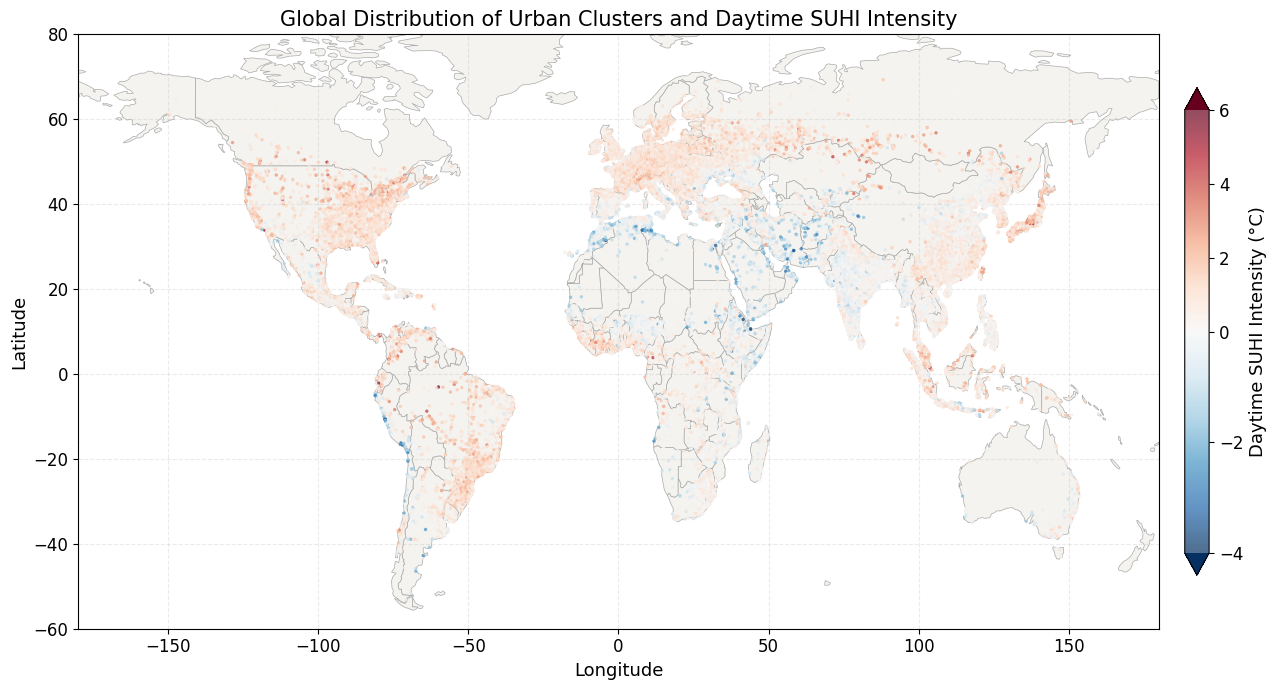

In [3]:
import json
import urllib.request
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection
from matplotlib.colors import TwoSlopeNorm

# --- GLOBAL OVERVIEW MAP OF URBAN CLUSTERS ---
# Load world basemap
geojson_url = "https://raw.githubusercontent.com/python-visualization/folium/master/examples/data/world-countries.json"
req = urllib.request.Request(geojson_url, headers={'User-Agent': 'Mozilla/5.0'})
with urllib.request.urlopen(req) as response:
    world_data = json.loads(response.read().decode())

world_patches = []
for feature in world_data['features']:
    geom_type = feature['geometry']['type']
    coords = feature['geometry']['coordinates']
    if geom_type == 'Polygon':
        for ring in coords:
            world_patches.append(Polygon(ring, closed=True))
    elif geom_type == 'MultiPolygon':
        for poly in coords:
            for ring in poly:
                world_patches.append(Polygon(ring, closed=True))

fig, ax = plt.subplots(figsize=(14, 7))

# Add basemap layer
country_collection = PatchCollection(
    world_patches,
    facecolor='#f4f3ef',
    edgecolor='#aaaaaa',
    linewidth=0.5,
    zorder=1
)
ax.add_collection(country_collection)

# Center the diverging colormap at 0 °C so heat islands (red) and cool islands (blue) stand out clearly
norm = TwoSlopeNorm(vmin=-4, vcenter=0, vmax=6)

sc = ax.scatter(
    meta_data['Lon'],
    meta_data['Lat'],
    c=meta_data['SUHI_Day'],
    cmap='RdBu_r',
    norm=norm,
    s=6,
    alpha=0.7,
    edgecolors='none',
    zorder=2
)

cbar = plt.colorbar(sc, ax=ax, pad=0.02, shrink=0.82, extend='both')
cbar.set_label('Daytime SUHI Intensity (°C)', fontsize=13)
cbar.ax.tick_params(labelsize=12)

ax.set_xlim(-180, 180)
ax.set_ylim(-60, 80)
ax.set_title('Global Distribution of Urban Clusters and Daytime SUHI Intensity', fontsize=15)
ax.set_xlabel('Longitude', fontsize=13)
ax.set_ylabel('Latitude', fontsize=13)
ax.grid(True, linestyle='--', alpha=0.25)
ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.show()

<h5 align="center">Global spatial distribution of the ~29,000 urban clusters in the dataset, colored by daytime surface urban heat island (SUHI) intensity (°C). Positive values (red) indicate urban surfaces warmer than their rural surroundings, whereas negative values (blue) indicate daytime urban cool islands, commonly observed in arid regions.</h5>

---


# PATTERN EXTRACTION AND DIMENSIONALITY REDUCTION

---

# UNDERSTANDING PRINCIPAL COMPONENT ANALYSIS (PCA)

PCA, often called empirical orthogonal function (EOF) in geophysics (Thompson & Wallace, 1998; Hannachi et al., 2007; Wheeler & Maloney, 2013), has been a trusted tool in the scientist's toolkit for decades. Put simply, it allows us to simplify complex datasets. It finds the "major patterns" (modes of variability) without throwing away important information.

**How it works**

Imagine trying to draw a straight line through a cloud of data points so that the line touches as much of the data as possible.
1.  **PC1:** This first line is your first principal component. It represents the strongest pattern in your data.
2.  **PC2:** The second line must be perpendicular (orthogonal) to the first, capturing the *next* strongest pattern.

Mathematically, **PC1** is the direction that maximises the variance of the projected data. This is equivalent to minimizing the average squared distance between each point and its projection onto the line.

**A critical caveat**

PCA assumes the world is **linear**. As we know, environmental processes are often **non-linear**. When we use PCA, we are essentially trying to describe curved, complex shapes using straight lines. We must be careful not to lose physical meaning in this translation.

**In practice**
* We can look at the **time series** of a component to see *when* a pattern happens.
* We can use the components to **reconstruct** the data, keeping the signal and leaving out the noise.

Generally, a PCA can be calculated mathematically, but can also be isolated iteratively by rotating a line until the distance between the points and the line is minimized. This is PC1.

Once PC1 is found, PC2 is defined as the direction perpendicular to it:


<div align="center">
  <img src="Img/PCA_Watermark.png" alt="Schematic of Principal Component Analysis" width="80%">
</div>

<h5 align="center">Schematic of PCA (was developed using Gemini Pro guided by author)</h5>

# IMPLEMENTING PCA ON OUR DATA

PCA is our baseline. It assumes that the relationships between our variables (e.g., urban-rural differences in various biophysical properties) are **linear** and **global** (the same everywhere).

We will project our 7-dimensional data down to 2 dimensions to see if distinct clusters emerge.

PCA MSE: 0.55435


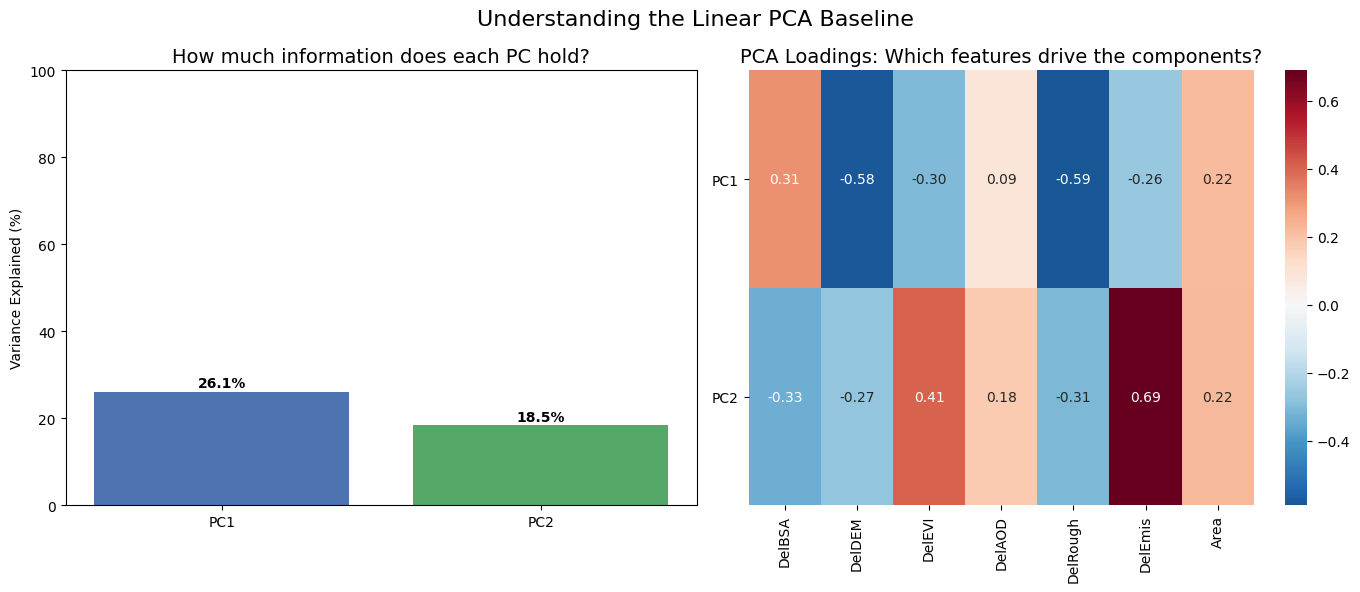

In [4]:
# 1. Run PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
X_recon_pca = pca.inverse_transform(X_pca)
mse_pca = mean_squared_error(X_scaled, X_recon_pca)
print(f"PCA MSE: {mse_pca:.5f}")

# --- PCA DIAGNOSTICS DASHBOARD ---
plt.figure(figsize=(14, 6))

# Subplot 1: Explained Variance
plt.subplot(1, 2, 1)
variance_ratio = pca.explained_variance_ratio_ * 100
plt.bar(['PC1', 'PC2'], variance_ratio, color=['#4c72b0', '#55a868'])
plt.title('How much information does each PC hold?', fontsize=14)
plt.ylabel('Variance Explained (%)')
plt.ylim(0, 100)
for i, v in enumerate(variance_ratio):
    plt.text(i, v + 1, f"{v:.1f}%", ha='center', fontweight='bold')

# Subplot 2: Feature Loadings Heatmap
plt.subplot(1, 2, 2)
loadings = pd.DataFrame(pca.components_, columns=feature_cols, index=['PC1', 'PC2'])
sns.heatmap(loadings, annot=True, cmap='RdBu_r', center=0, fmt='.2f')
plt.title('PCA Loadings: Which features drive the components?', fontsize=14)
plt.yticks(rotation=0)

plt.suptitle("Understanding the Linear PCA Baseline", fontsize=16)
plt.tight_layout()
plt.show()

<h5 align="center">Linear PCA diagnostics showing the percentage of total variance explained by PC1 and PC2 (left) and the feature loadings across the seven urban biophysical drivers (right).</h5>

---

# BEYOND LINEARITY: AUTOENCODERS

While PCA is a powerful tool, it has a major limitation: it assumes patterns are linear (straight lines). To capture the complex, curving relationships often found in physical systems, we turn to **autoencoders**.

An autoencoder is a specific type of neural network. You can think of it as a "data compression" machine.

**How it works**
1.  **The Encoder:** We feed our full dataset ($x$) into the network.
2.  **The Bottleneck:** The network squeezes this data through a tiny hidden layer ($u$). This forces the model to throw away noise and keep only the most important patterns.
3.  **The Decoder:** The network tries to recreate the original data ($x'$) using only the information saved in the bottleneck.

If the network is linear, the result is identical to PCA. However, by making the network **non-linear**, we allow it to learn curved patterns.

**Visualizing the Difference**

The diagrams below illustrate this process. First, the network structure:


<div align="center">
  <img src="Img/Auto_Watermark.png" alt="Autoencoder structure" width="80%">
</div>

<h5 align="center">Schematic of structure of an autoencoder (was developed using Gemini Pro guided by author)
</h5>

Second, the result. In the plot below, we have data spread across three dimensions.
* **PCA (Dashed Line):** Tries to summarize the data with a straight stick. It misses the curvature.
* **Autoencoder (Solid Line):** Bends to follow the actual shape of the data, capturing the physics more accurately.


<div align="center">
  <img src="Img/Auto_spread_Watermark.png" alt="Schematic of spread of the data showing PCA (Dashed Line) vs. Autoencoder (Solid Line)" width="80%">
</div>

<h5 align="center">Schematic of the spread of the data showing PCA (Dashed Line) vs. Autoencoder (Solid Line) (was developed using Gemini Pro guided by author)
</h5>

# LINEAR VERSUS NON-LINEAR AUTOENCODERS

Now we will do the same thing as before, but using an autoencoder. First, we will train a linear autoencoder, which should be structurally very similar to a PCA. Then, we will check if being able to capture non-linearities (using a non-linear activation function; also called a deep autoencoder) leads to improved performance. 

**Note:** For the sake of simplicity, we choose a fixed model architecture for the autoencoder in this chapter. However, autoencoders have many adjustable parameters, both structural (bottleneck size, number of layers, and nodes per layer) and for the learning process (learning rate, batch size, number of epochs) and for real use cases, one would tune the hyperparameters to find the best fit for the research problem.

In [5]:
# Reset seed immediately before model construction to lock reproducibility
np.random.seed(42)
tf.random.set_seed(42)

input_dim = X_scaled.shape[1]
encoding_dim = 2

# --- Linear Autoencoder (The Control Group) ---
input_lin = Input(shape=(input_dim,))
encoded_lin = Dense(64, activation='linear')(input_lin)
bottleneck_lin = Dense(encoding_dim, activation='linear')(encoded_lin)
decoded_lin = Dense(64, activation='linear')(bottleneck_lin)
output_lin = Dense(input_dim, activation='linear')(decoded_lin)

linear_ae = Model(input_lin, output_lin)
linear_ae.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
linear_ae.fit(X_scaled, X_scaled, epochs=30, batch_size=256, verbose=0)

# Evaluate Linear
X_recon_lin = linear_ae.predict(X_scaled, verbose=0)
mse_lin = mean_squared_error(X_scaled, X_recon_lin)
print(f"Linear AE MSE: {mse_lin:.5f} (Compare to PCA: {mse_pca:.5f})")

# --- Deep Non-Linear Autoencoder (The Challenger) ---
# Explicitly reset seeds right before building the model so its initialization is invariant
tf.keras.utils.set_random_seed(42)

input_nl = Input(shape=(input_dim,))
encoded_nl = Dense(64, activation='relu')(input_nl) # ReLU allows non-linearities; being a piecewise linear function!
encoded_nl = Dense(32, activation='relu')(encoded_nl)
bottleneck_nl = Dense(encoding_dim, activation='linear', name='bottleneck')(encoded_nl)
decoded_nl = Dense(32, activation='relu')(bottleneck_nl)
decoded_nl = Dense(64, activation='relu')(decoded_nl)
output_nl = Dense(input_dim, activation='linear')(decoded_nl)

nonlinear_ae = Model(input_nl, output_nl)
encoder_nl = Model(input_nl, bottleneck_nl) # For extracting the map later

nonlinear_ae.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
print("Training deep autoencoder...")
nonlinear_ae.fit(X_scaled, X_scaled, epochs=50, batch_size=256, verbose=0)

# Evaluate Non-Linear
X_recon_nl = nonlinear_ae.predict(X_scaled, verbose=0)
mse_nl = mean_squared_error(X_scaled, X_recon_nl)
print(f"Non-Linear AE MSE: {mse_nl:.5f}")

Linear AE MSE: 0.55466 (Compare to PCA: 0.55435)
Training deep autoencoder...
Non-Linear AE MSE: 0.16953


201/907 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

249/907 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

295/907 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

347/907 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

394/907 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

... (31 outputs left out)

882/907 ━━━━━━━━━━━━━━━━━━━━ 0s 923us/step

907/907 ━━━━━━━━━━━━━━━━━━━━ 0s 959us/step

907/907 ━━━━━━━━━━━━━━━━━━━━ 1s 974us/step


Non-Linear AE MSE: 0.19458


As you can see above, the reconstruction error for the linear autoencoder (MSE = 0.55466) is roughly equivalent to that of PCA (MSE = 0.55435), while the deep non-linear autoencoder achieves a substantially lower error (MSE = 0.16953). It should be noted that for a predictive model rather than a simple exploratory one, the accuracy assessment for the deep learning architecture would be done on a held-out portion of the dataset not used during model training.

**Note:** The 64-dimensional hidden layer used above is unnecessary here since we are only dealing with 7 features. 
However, we keep this in the code as an illustration for higher dimensionality use cases.

# SCIENTIFIC VALIDATION (URBAN-RURAL VEGETATION ANOMALIES)

A primary physical driver of the SUHI effect is the contrast in vegetative cover between an urban core and its rural surroundings. Because vegetation provides crucial cooling through evapotranspiration and shading, regions with high urbanization-induced vegetation loss typically experience the most severe heat island intensities.

While unsupervised models like PCA and autoencoders help us discover hidden structures in our data without needing labels, it is crucial to validate these representations against known physical phenomena. 

In this section, we evaluate whether our models successfully captured these vegetation gradients.

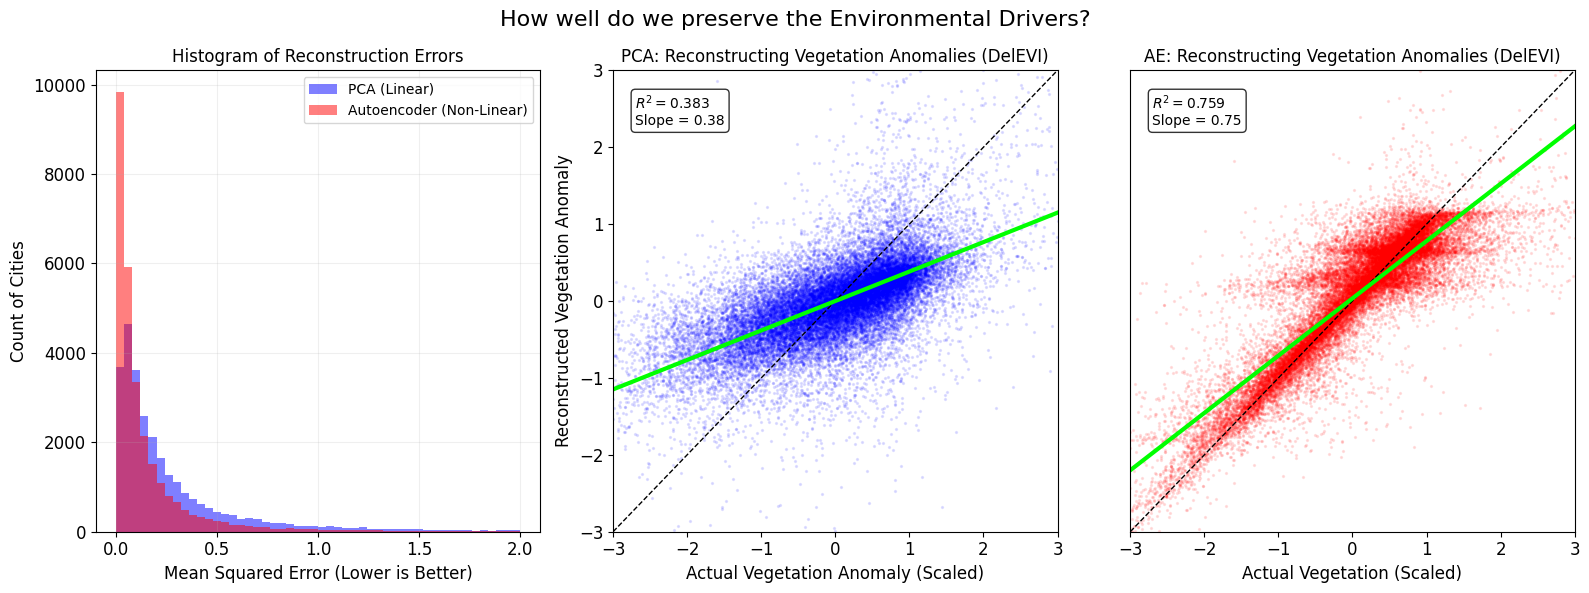

In [6]:
# --- ERROR ANALYSIS DASHBOARD ---
plt.figure(figsize=(16, 6))

# Subplot 1: Reconstruction Error Distribution
pca_errors = np.mean(np.square(X_scaled - X_recon_pca), axis=1)
ae_errors = np.mean(np.square(X_scaled - X_recon_nl), axis=1)

plt.subplot(1, 3, 1)
plt.hist(pca_errors, bins=50, alpha=0.5, label='PCA (Linear)', color='blue', range=(0, 2))
plt.hist(ae_errors, bins=50, alpha=0.5, label='Autoencoder (Non-Linear)', color='red', range=(0, 2))
plt.title('Histogram of Reconstruction Errors', fontsize=12)
plt.xlabel('Mean Squared Error (Lower is Better)', fontsize=12)
plt.ylabel('Count of Cities', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.2)
plt.tick_params(axis='x', labelsize=12)
plt.tick_params(axis='y', labelsize=12)

# Subplot 2 & 3: Actual vs Reconstructed DRIVER
# We track 'DelEVI' (Vegetation Diff) because it is a complex, non-linear driver.
# If we can reconstruct vegetation patterns accurately, we understand the city's green structure.
feat_idx = feature_cols.index('DelEVI') 
actual_feat = X_scaled[:, feat_idx]
pca_feat = X_recon_pca[:, feat_idx]
ae_feat = X_recon_nl[:, feat_idx]

# PCA Scatter
plt.subplot(1, 3, 2)
plt.scatter(actual_feat, pca_feat, alpha=0.1, s=2, color='blue')
plt.plot([-3, 3], [-3, 3], 'k--', lw=1)
plt.title(f'PCA: Reconstructing Vegetation Anomalies (DelEVI)', fontsize=12)
plt.xlabel('Actual Vegetation Anomaly (Scaled)', fontsize=12)
plt.ylabel('Reconstructed Vegetation Anomaly', fontsize=12)
plt.xlim(-3, 3); plt.ylim(-3, 3)
plt.tick_params(axis='x', labelsize=12)
plt.tick_params(axis='y', labelsize=12)

# Line of Best Fit & R2 for PCA
m_pca, b_pca = np.polyfit(actual_feat, pca_feat, 1)
r2_pca = np.corrcoef(actual_feat, pca_feat)[0, 1]**2
x_vals = np.array([-3, 3])
plt.plot(x_vals, m_pca * x_vals + b_pca, color='lime', lw=3, label='Best Fit')
plt.text(0.05, 0.95, f'$R^2 = {r2_pca:.3f}$\nSlope = {m_pca:.2f}', 
         transform=plt.gca().transAxes, verticalalignment='top', 
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# AE Scatter
plt.subplot(1, 3, 3)
plt.scatter(actual_feat, ae_feat, alpha=0.1, s=2, color='red')
plt.plot([-3, 3], [-3, 3], 'k--', lw=1)
plt.title(f'AE: Reconstructing Vegetation Anomalies (DelEVI)', fontsize=12)
plt.xlabel('Actual Vegetation (Scaled)', fontsize=12)
plt.yticks([])
plt.xlim(-3, 3); plt.ylim(-3, 3)
plt.tick_params(axis='x', labelsize=12)
plt.tick_params(axis='y', labelsize=12)


# Line of Best Fit & R2 for autoencoder (AE)
m_ae, b_ae = np.polyfit(actual_feat, ae_feat, 1)
r2_ae = np.corrcoef(actual_feat, ae_feat)[0, 1]**2
x_vals = np.array([-3, 3])
plt.plot(x_vals, m_ae * x_vals + b_ae, color='lime', lw=3, label='Best Fit')
plt.text(0.05, 0.95, f'$R^2 = {r2_ae:.3f}$\nSlope = {m_ae:.2f}', 
         transform=plt.gca().transAxes, verticalalignment='top', 
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))


plt.suptitle("How well do we preserve the Environmental Drivers?", fontsize=16)
plt.tight_layout()
plt.show()


<h5 align="center">Comparison of reconstruction errors between linear PCA and the deep non-linear autoencoder. Left: distribution of mean squared reconstruction errors across all urban clusters. Center and right: actual versus reconstructed scaled vegetation anomalies (DelEVI), showing the 1:1 reference line (dashed black) and the ordinary least-squares linear best-fit line (solid lime green) with corresponding R² and slope values.</h5>

As expected from the overall evaluation, the autoencoder performs much better at reproducing both the range of change in `DelEVI` (the bright lime green linear best-fit line has a slope closer to the dashed 1:1 line) and its variability (higher $R^2$).

# SCIENTIFIC VALIDATION (REGIME AND URBAN HEAT DETECTION)

Continuing with the goal of independent validation, we project our model's learned components and clusters against known regimes of the SUHI, specifically its variability with **climate zones** and **coastal proximity**.

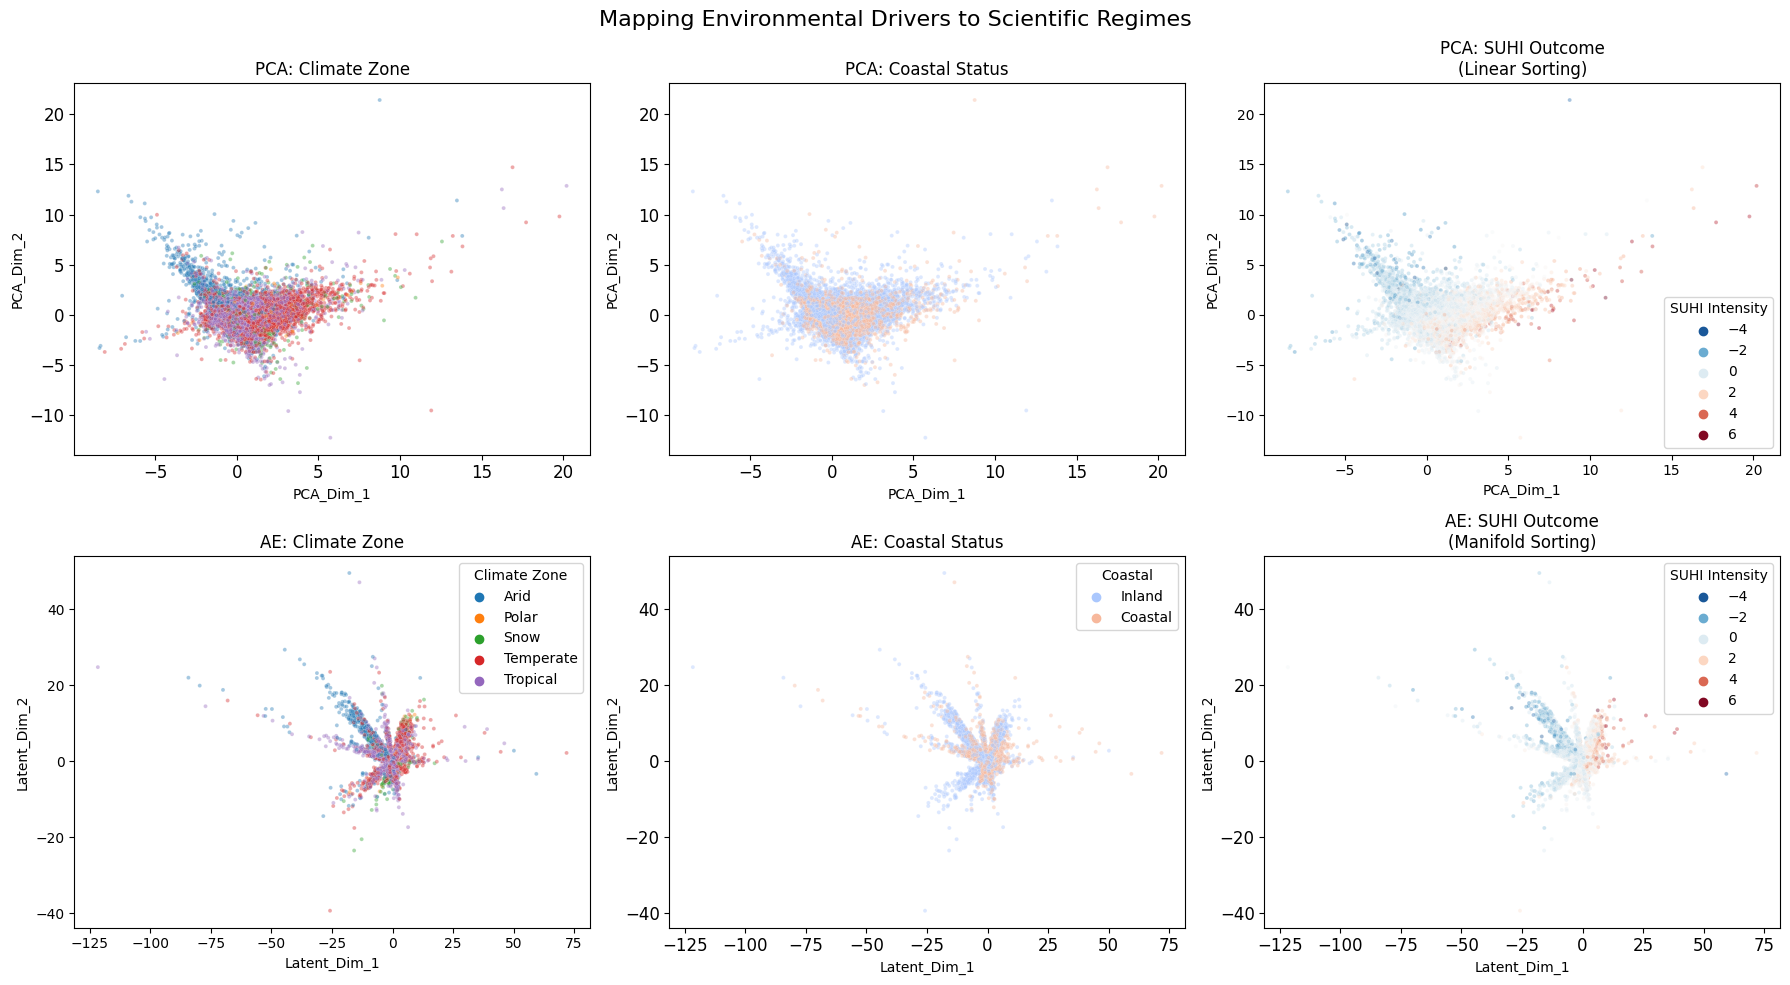

In [7]:
# Extract the latent coordinates
X_latent = encoder_nl.predict(X_scaled, verbose=0)

# 1. Perform Clustering on the Latent Space
# Using a Gaussian Mixture Model, we ask: "Find 5 natural probability distributions (Regimes) in this data."
gmm = GaussianMixture(n_components=5, random_state=42)
latent_clusters = gmm.fit_predict(X_latent)

# Create a master plotting DataFrame merging coordinates with labels
plot_df = pd.DataFrame(X_latent, columns=['Latent_Dim_1', 'Latent_Dim_2'])
plot_df['PCA_Dim_1'] = X_pca[:, 0]
plot_df['PCA_Dim_2'] = X_pca[:, 1]
plot_df['Climate Zone'] = meta_data['Clim_zone']
plot_df['Coastal'] = meta_data['Coastal?'].map({True: 'Coastal', False: 'Inland'})
plot_df['SUHI Intensity'] = meta_data['SUHI_Day'] # The Outcome Variable
plot_df['Cluster'] = latent_clusters
plot_df['Lat'] = meta_data['Lat']
plot_df['Lon'] = meta_data['Lon']

# --- SCIENTIFIC REGIMES ---
# We compare how well PCA vs Autoencoder separates actual scientific categories.
fig, axes = plt.subplots(2, 3, figsize=(18, 10)) # Expanded to 3 columns

# Row 1: PCA (Linear)
sns.scatterplot(data=plot_df, x='PCA_Dim_1', y='PCA_Dim_2', hue='Climate Zone', 
                ax=axes[0,0], palette='tab10', alpha=0.4, s=8, legend=False)
axes[0,0].set_title('PCA: Climate Zone', fontsize=12)

sns.scatterplot(data=plot_df, x='PCA_Dim_1', y='PCA_Dim_2', hue='Coastal', 
                ax=axes[0,1], palette='coolwarm', alpha=0.4, s=8, legend=False)
axes[0,1].set_title('PCA: Coastal Status', fontsize=12)

# New Column: Does the driver-based map explain the Outcome (SUHI)?
sns.scatterplot(data=plot_df, x='PCA_Dim_1', y='PCA_Dim_2', hue='SUHI Intensity', 
                ax=axes[0,2], palette='RdBu_r', alpha=0.4, s=8)
axes[0,2].set_title('PCA: SUHI Outcome\n(Linear Sorting)', fontsize=12)


# Row 2: Autoencoder (Non-Linear)
sns.scatterplot(data=plot_df, x='Latent_Dim_1', y='Latent_Dim_2', hue='Climate Zone', 
                ax=axes[1,0], palette='tab10', alpha=0.4, s=8)
axes[1,0].set_title('AE: Climate Zone', fontsize=12)

sns.scatterplot(data=plot_df, x='Latent_Dim_1', y='Latent_Dim_2', hue='Coastal', 
                ax=axes[1,1], palette='coolwarm', alpha=0.4, s=8)
axes[1,1].set_title('AE: Coastal Status', fontsize=12)

sns.scatterplot(data=plot_df, x='Latent_Dim_1', y='Latent_Dim_2', hue='SUHI Intensity', 
                ax=axes[1,2], palette='RdBu_r', alpha=0.4, s=8)
axes[1,2].set_title('AE: SUHI Outcome\n(Manifold Sorting)', fontsize=12)

axes[0,0].tick_params(axis='x', labelsize=12)
axes[0,0].tick_params(axis='y', labelsize=12)

axes[0,1].tick_params(axis='x', labelsize=12)
axes[0,1].tick_params(axis='y', labelsize=12)

axes[1,1].tick_params(axis='x', labelsize=12)
axes[1,1].tick_params(axis='y', labelsize=12)

axes[1,2].tick_params(axis='x', labelsize=12)
axes[1,2].tick_params(axis='y', labelsize=12)


plt.suptitle("Mapping Environmental Drivers to Scientific Regimes", fontsize=16)
plt.tight_layout()
plt.show()


<h5 align="center">Comparison of 2D projections from linear PCA (top row) and the non-linear autoencoder latent space (bottom row), colored independently by Köppen-Geiger climate zone (left), coastal versus inland status (center), and daytime SUHI intensity (right).</h5>

Note how the PCA clusters look more like blobs (essentially multivariate normal distributions) than those from the autoencoders. This is expected because PCA is a linear technique that can only find linear patterns, while autoencoders can capture complex non-linear relationships in data. It does seem like arid climate shows up as somewhat distinct blobs for both methods. But let us look into this deeper.

# SCIENTIFIC VALIDATION (GEOGRAPHIC DISTRIBUTIONS)

Next, we evaluate our PCA and autoencoder models against broad **geographic distributions**. By projecting spatial metadata, such as background climate zones and coastal proximity, onto our lower-dimensional clusters, we can observe whether the algorithms naturally separate cities based on their physical geography. 

If distinct clusters emerge along these geographic boundaries, it indicates that the models have successfully internalized the macro-scale spatial drivers of the SUHI without ever being explicitly trained on them.

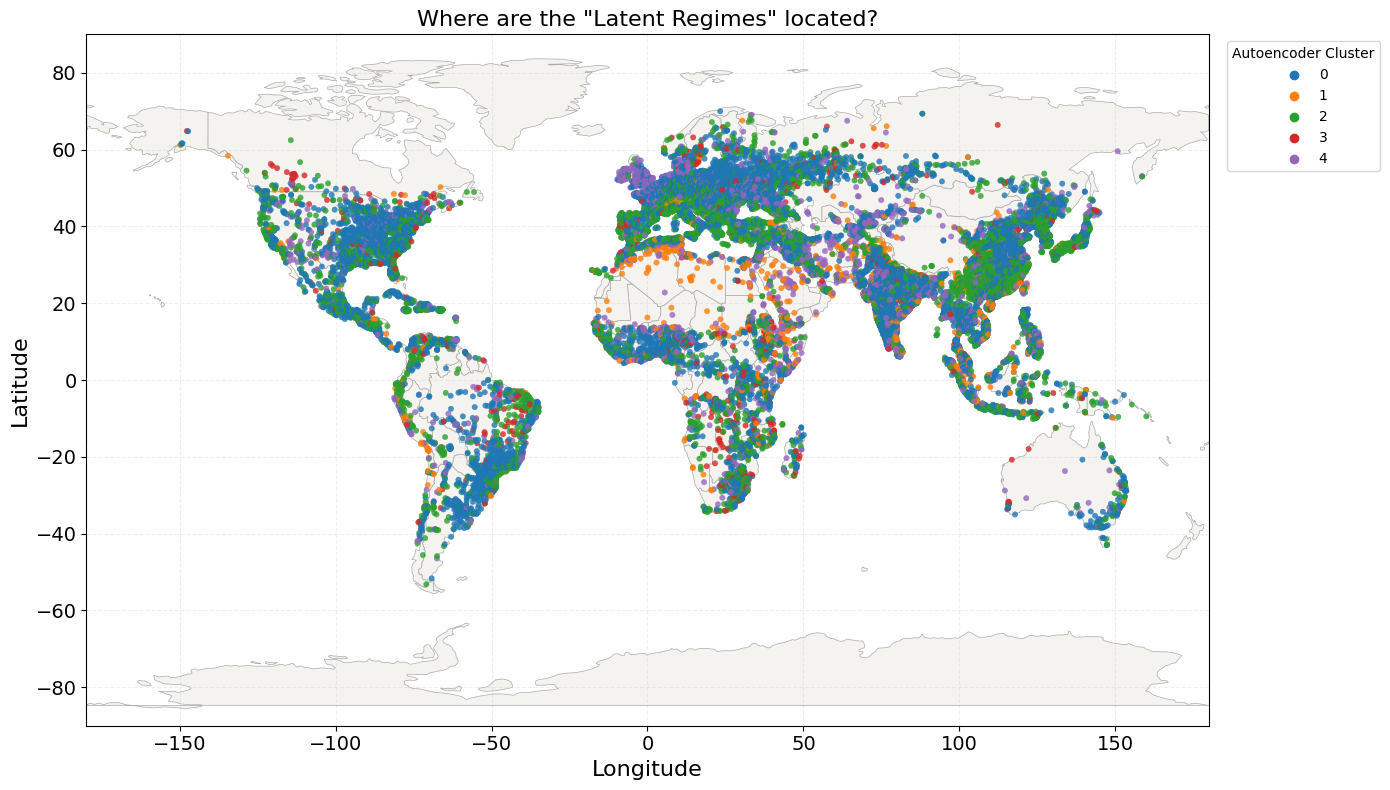

In [8]:
import json
import urllib.request
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection

# --- GEOGRAPHIC MAPPING OF LATENT CLUSTERS ---
# We map the 5 mathematically discovered clusters back to the real world.
# We add a physical basemap underneath to provide geographic context and coastline boundaries.
geojson_url = "https://raw.githubusercontent.com/python-visualization/folium/master/examples/data/world-countries.json"
req = urllib.request.Request(geojson_url, headers={'User-Agent': 'Mozilla/5.0'})
with urllib.request.urlopen(req) as response:
    world_data = json.loads(response.read().decode())

fig, ax = plt.subplots(figsize=(14, 8))

patches = []
for feature in world_data['features']:
    geom_type = feature['geometry']['type']
    coords = feature['geometry']['coordinates']
    
    if geom_type == 'Polygon':
        for ring in coords:
            patches.append(Polygon(ring, closed=True))
    elif geom_type == 'MultiPolygon':
        for poly in coords:
            for ring in poly:
                patches.append(Polygon(ring, closed=True))

country_collection = PatchCollection(
    patches, 
    facecolor='#f4f3ef', 
    edgecolor='#aaaaaa', 
    linewidth=0.5, 
    zorder=1
)
ax.add_collection(country_collection)

sns.scatterplot(
    data=plot_df, 
    x='Lon', 
    y='Lat', 
    hue='Cluster', 
    palette='tab10', 
    s=15, 
    alpha=0.8, 
    edgecolor=None, 
    ax=ax, 
    zorder=2
)

ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)

plt.title('Where are the "Latent Regimes" located?', fontsize=16)
plt.xlabel('Longitude', fontsize=16)
plt.ylabel('Latitude', fontsize=16)
plt.legend(title='Autoencoder Cluster', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.2)

plt.tick_params(axis='x', labelsize=14)
plt.tick_params(axis='y', labelsize=14)

plt.tight_layout()
plt.show()

<h5 align="center">Global geographic distribution of the five unsupervised urban clusters identified by fitting a Gaussian mixture model to the 2D autoencoder latent space.</h5>

This would require a bit more information (see below), but we see that the clusters are not necessarily randomly distributed. As an example, we see a lot of urban areas belonging to cluster 0 in India.

# SCIENTIFIC VALIDATION (CLUSTER COMPOSITION)

Having visualized how our unsupervised models map cities across geographic gradients, we now turn to a more quantitative analysis: breaking down the internal makeup of the clusters themselves. 

Here, we examine the **cluster composition** to determine exactly *who* ended up in each group. By calculating the proportions of different climate zones, coastal designations, or SUHI intensities within each mathematically derived cluster, we can assign them physical meaning. 

This step is critical for interpretation. An unsupervised model will always group data points together based on mathematical similarities, but it is up to us to determine if those groupings represent physically distinct typologies of samples in the real world. The breakdown below helps us answer the key question: What physical characteristics define each of these clusters?


--- CLUSTER COMPOSITION (Fraction by Climate Zone) ---
Climate Zone      Arid     Polar      Snow  Temperate  Tropical
Cluster                                                        
0             0.141321  0.012928  0.130775   0.437708  0.277267
1             0.348474  0.011169  0.058824   0.329114  0.252420
2             0.091163  0.033997  0.109792   0.549657  0.215392
3             0.177590  0.010571  0.140592   0.357294  0.313953
4             0.301518  0.007005  0.100117   0.361062  0.230298

--- COASTAL DETECTION (Fraction by Binary Cluster) ---
Coastal   Coastal    Inland
row_0                      
0        0.082417  0.917583
1        0.187686  0.812314


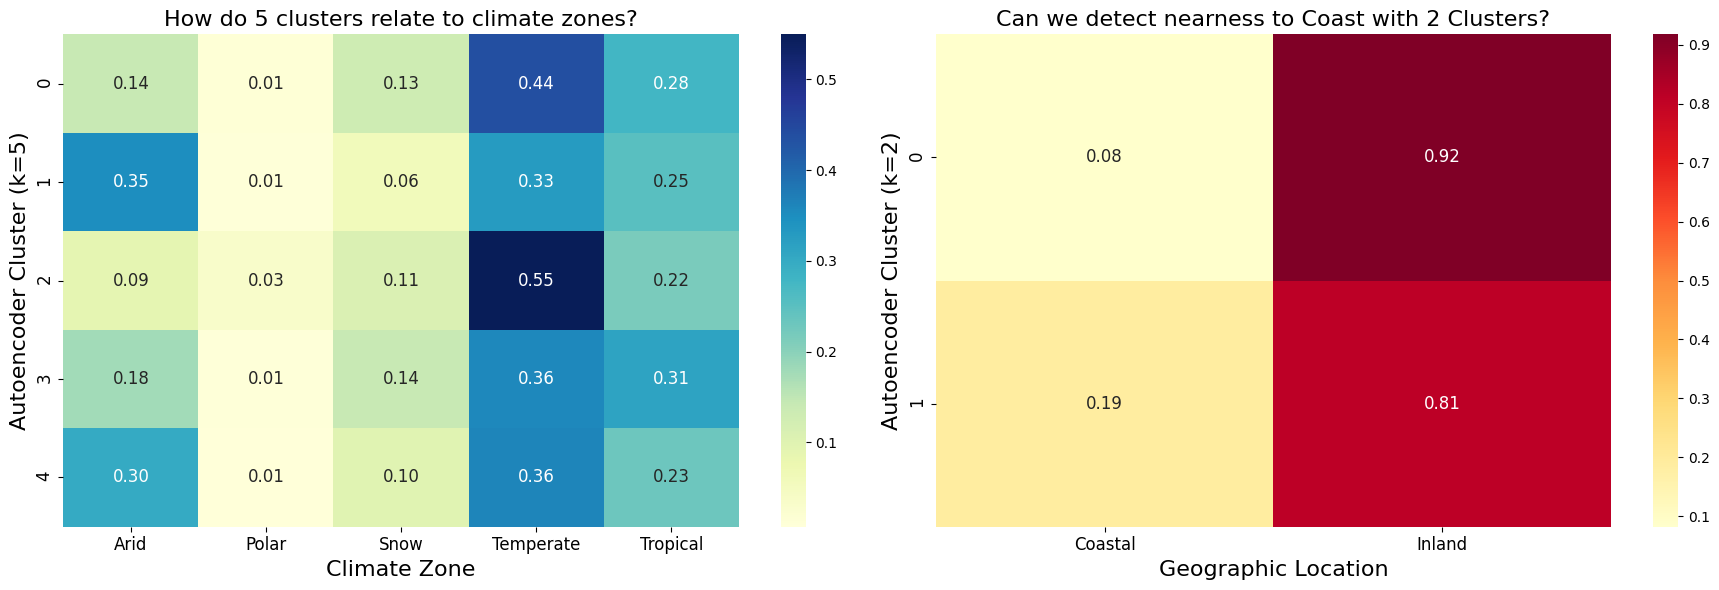

In [9]:

# --- CALCULATE CLUSTER COMPOSITION BY CLIMATE ZONE ---
# We compute what fraction of each autoencoder cluster belongs to which Climate Zone.

cluster_composition = pd.crosstab(plot_df['Cluster'], plot_df['Climate Zone'], normalize='index')

print("\n--- CLUSTER COMPOSITION (Fraction by Climate Zone) ---")
print(cluster_composition)

# --- ANALYSIS 2: COASTAL VS INLAND (USING 2 CLUSTERS) ---
# To test if the autoencoder specifically separates Coastal from Inland cities,
# we force a new clustering with only 2 components (Binary split).
gmm_coastal = GaussianMixture(n_components=2, random_state=42)
coastal_clusters = gmm_coastal.fit_predict(X_latent)

coastal_composition = pd.crosstab(coastal_clusters, plot_df['Coastal'], normalize='index')

print("\n--- COASTAL DETECTION (Fraction by Binary Cluster) ---")
print(coastal_composition)

# --- COMPOSITION HEATMAPS ---
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Plot 5: Climate Zone Breakdown (5 Cluster are chosen to match the five broad Köppen-Geiger climate zones)
sns.heatmap(cluster_composition, annot=True, fmt=".2f", cmap="YlGnBu", annot_kws={"size": 12}, ax=axes[0])
axes[0].set_title('How do 5 clusters relate to climate zones?', fontsize=16)
axes[0].set_ylabel('Autoencoder Cluster (k=5)', fontsize=16)
axes[0].set_xlabel('Climate Zone', fontsize=16)

# Plot 6: Coastal Breakdown (2 Clusters are used as a binary coastal/inland split)
sns.heatmap(coastal_composition, annot=True, fmt=".2f", cmap="YlOrRd", annot_kws={"size": 12}, ax=axes[1])
axes[1].set_title('Can we detect nearness to Coast with 2 Clusters?', fontsize=16)
axes[1].set_ylabel('Autoencoder Cluster (k=2)', fontsize=16)
axes[1].set_xlabel('Geographic Location', fontsize=16)

axes[0].tick_params(axis='x', labelsize=12)
axes[0].tick_params(axis='y', labelsize=12)

axes[1].tick_params(axis='x', labelsize=12)
axes[1].tick_params(axis='y', labelsize=12)


plt.tight_layout()
plt.show()

<h5 align="center">Quantitative breakdown of unsupervised autoencoder clusters by independent geographic metadata, showing the fraction of cities in each cluster belonging to each Köppen-Geiger climate zone (left) and the coastal versus inland split for a two-cluster solution (right).</h5>

Similarly, looking at the clusters after they have been grouped shows that the dominant clusters do generally correspond to distinct climate zones. For instance, the cluster with highest fraction of temperate cities is number 2, and the one with the most arid cities is number 1, the one with the most tropical cities is number 3. This suggests that the autoencoder has managed to somewhat separate the cities into their climate regimes using the combination of urban characteristics.

For the distribution of coastal and inland cities, the separation is not as obvious.

It is important to **note that the climate zones of the urban clusters, and their coastal information were never provided to the autoencoder.** It detected these modes of variability in an unsupervised fashion, which is very encouraging for new scientific discovery.

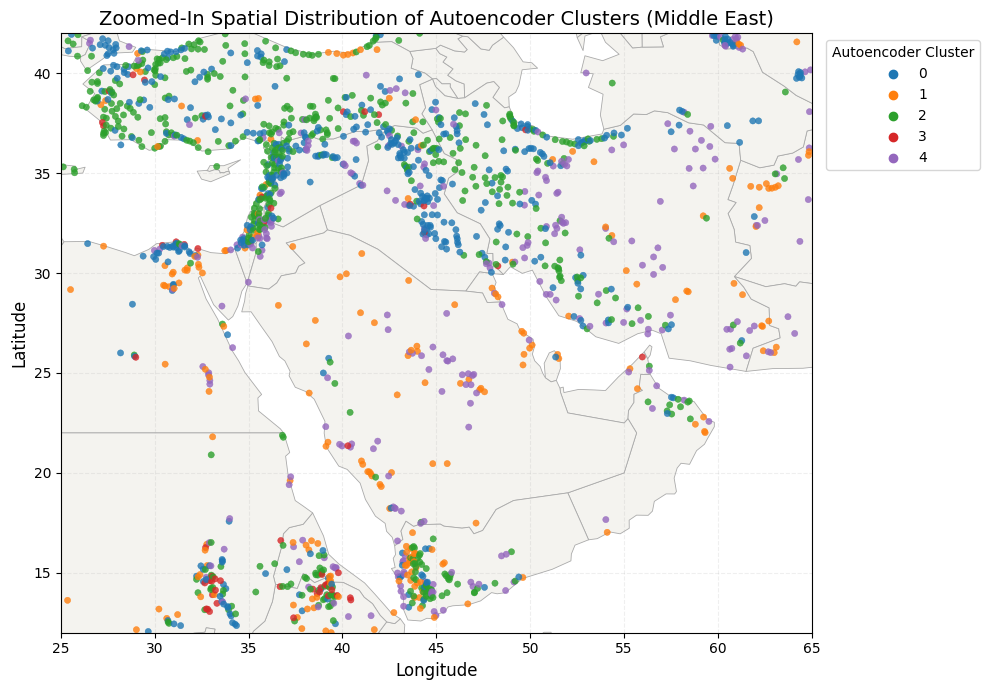

In [10]:
# Regional distribution of unsupervised autoencoder clusters across the Middle East
fig, ax = plt.subplots(figsize=(10, 7))
ax.add_collection(PatchCollection(patches, facecolor='#f4f3ef', edgecolor='#aaaaaa', linewidth=0.6, zorder=1))

# Filter to the Middle East
lon_min, lon_max = 25, 65
lat_min, lat_max = 12, 42
region_df = plot_df[plot_df['Lon'].between(lon_min, lon_max) & plot_df['Lat'].between(lat_min, lat_max)]

sns.scatterplot(
    data=region_df,
    x='Lon',
    y='Lat',
    hue='Cluster',
    hue_order=sorted(plot_df['Cluster'].unique()),
    palette='tab10',
    s=20,
    alpha=0.8,
    edgecolor=None,
    ax=ax,
    zorder=2
)

ax.set_xlim(lon_min, lon_max)
ax.set_ylim(lat_min, lat_max)
ax.set_title('Zoomed-In Spatial Distribution of Autoencoder Clusters (Middle East)', fontsize=14)
ax.set_xlabel('Longitude', fontsize=12)
ax.set_ylabel('Latitude', fontsize=12)
ax.legend(title='Autoencoder Cluster', bbox_to_anchor=(1.01, 1), loc='upper left')
ax.grid(True, linestyle='--', alpha=0.2)

plt.tight_layout()
plt.show()

<h5 align="center">Regional close-up of unsupervised autoencoder clusters across the Middle East.</h5>

Zooming into the Middle East illustrates how the autoencoder's unsupervised clusters track sharp regional climate gradients without ever receiving coordinates or climate labels during training. Across the arid interior of the Arabian Peninsula and along the Red Sea and Persian Gulf, cities are dominated by the two most arid-enriched groupings, namely Cluster 1 (orange; 35% arid) and Cluster 4 (purple; 30% arid). Moving north toward the Mediterranean Levant coast, Turkey, and the Caspian coast, cities transition sharply to temperate-dominated Cluster 2 (green; 55% temperate, 9% arid), while Cluster 0 (blue; 44% temperate, 14% arid) concentrates along the greener, irrigated Tigris–Euphrates basin and Nile Delta. Finally, Cluster 3 (red)—the group with the highest tropical share (31% tropical)—emerges primarily along the lower-latitude southern margins (such as Yemen, Sudan, and the Horn of Africa) and is virtually absent farther north.

# SCIENTIFIC VALIDATION (SURFACE URBAN HEAT ISLAND INTENSITIES)

Finally, we evaluate our unsupervised representations against the core phenomenon we are investigating: the **SUHI intensity** itself. 

Because algorithms like PCA and autoencoders are unsupervised, they group data based purely on underlying patterns in the input features. They do not use target labels during training and have no explicit knowledge of which cities actually experience the most severe heat. 

In this section, we overlay the observed SUHI intensities onto our learned clusters and lower-dimensional spaces. What we are looking for is a clear gradient or stratification. If the models successfully captured the compounding physical, climatic, and geographic drivers of urban heat, we should see the most severe SUHI naturally segregating into specific clusters. This step confirms whether the mathematical structures discovered by the algorithms are genuinely predictive of the physical severity of the SUHI.


--- AVERAGE HEAT INTENSITY BY CLUSTER ---
Cluster
1    0.173813
4    0.263813
0    0.417530
3    0.605366
2    0.627325
Name: SUHI Intensity, dtype: float64


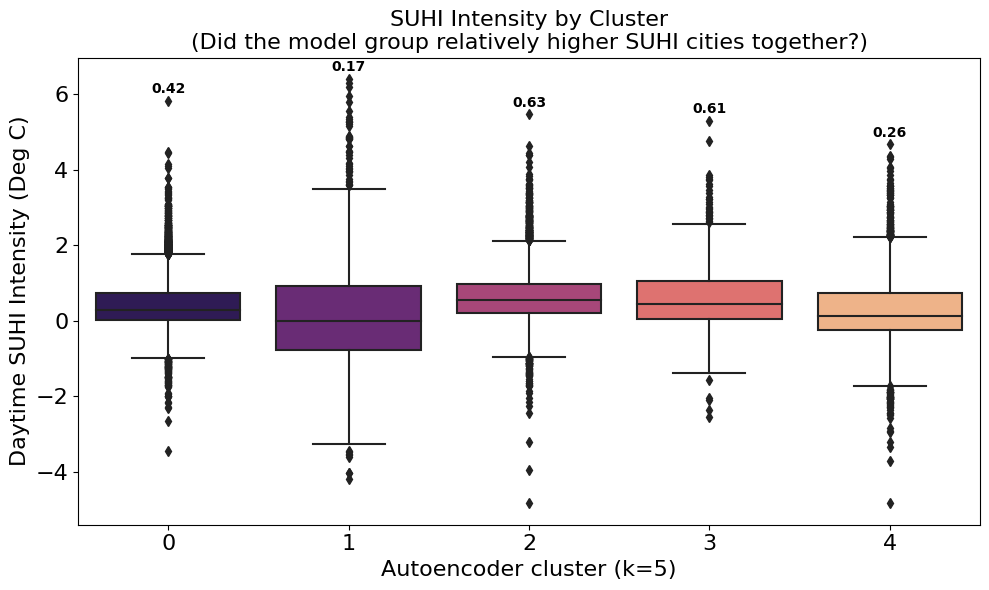

In [11]:
# --- SUHI OUTCOME BY CLUSTER ---
# The model never saw 'SUHI_Day' during training.
# Does the "Environmental Regime" (Cluster) predict how hot the city is?
# We check the "location" of each cluster on the SUHI spectrum.
suhi_by_cluster = plot_df.groupby('Cluster')['SUHI Intensity'].mean().sort_values()
print("\n--- AVERAGE HEAT INTENSITY BY CLUSTER ---")
print(suhi_by_cluster)

# --- OUTCOME DASHBOARD ---
fig, axes = plt.subplots(1, figsize=(10, 6)) # Single plot for SUHI Intensity by Cluster

# SUHI Intensity Boxplot
# We visualize the distribution of heat for each cluster to see if they are distinct.
sns.boxplot(data=plot_df, x='Cluster', y='SUHI Intensity', palette='magma', ax=axes)
axes.set_title('SUHI Intensity by Cluster\n(Did the model group relatively higher SUHI cities together?)', fontsize=16)
axes.set_xlabel('Autoencoder cluster (k=5)', fontsize=16)
axes.set_ylabel('Daytime SUHI Intensity (Deg C)', fontsize=16)

axes.tick_params(axis='x', labelsize=16)
axes.tick_params(axis='y', labelsize=16)


# Calculate means indexed by Cluster ID (not sorted by value, to match plot order)
means = plot_df.groupby('Cluster')['SUHI Intensity'].mean()

# Iterate over the plot's x-tick labels to ensure we match the correct cluster
for i, label in enumerate(axes.get_xticklabels()):
    # Get the cluster name (e.g., 0, 1, 2) from the label
    # We cast to int assuming your clusters are numeric, remove int() if they are strings
    cluster_id = int(label.get_text()) 
    
    # Get the mean and the max value (for positioning)
    mean_val = means[cluster_id]
    max_val = plot_df[plot_df['Cluster'] == cluster_id]['SUHI Intensity'].max()
    
    # Place text: x=i, y=max_val + offset
    axes.text(i, max_val + 0.2, f'{mean_val:.2f}', 
              horizontalalignment='center', color='black', weight='bold')
# -------------------------------------------

plt.tight_layout()
plt.show()

<h5 align="center">Distribution of observed daytime SUHI intensity (°C) across the five unsupervised autoencoder clusters, with cluster means labeled above each boxplot.</h5>

Finally, we examine the daytime SUHI intensity of these different clusters detected by the autoencoder, and many of these results make physical sense, in line with the background climate dependence of the SUHI. For instance, the lowest SUHI intensity is for cluster 1, which we earlier saw was strongly associated with arid climate. This is consistent with the well known urban cool islands in desert climate (Chakraborty & Lee, 2019).

# CONCLUSION

This chapter highlights the importance of non-linear unsupervised learning techniques for examining highly non-linear environmental processes. While traditional statistical methods like PCA are useful for identifying dominant global modes of variability, they often fail to capture the intricate, non-linear interactions characteristic of complex biophysical systems. By utilizing a deep non-linear autoencoder, we successfully compressed high-dimensional urban climate data into a lower-dimensional latent space without significant loss of information. The resulting latent space allows for the identification of distinct urban "typologies"—clusters of cities with similar heat island behaviors governed by specific environmental drivers. This approach provides a powerful framework for formulating new hypotheses about climate regimes and urban planning strategies, demonstrating that modern machine learning can do more than just predict—it can help us emulate the fundamental structure of our environment when provided high quality datasets, often available from Earth observations.

# EXERCISE

Below, we propose a few alternate use cases to implement this workflow and questions on interpretations that can help the reader get a good understanding of autoencoders and their possible applications in this domain.

In [12]:

print("1. What is your interpretation of the cluster compositions seen in the figures above?")
print("2. Redo this entire analysis with a focus on the nighttime SUHI")
print("3. Instead of choosing known drivers of the SUHI, use as many features as possible derived from various sources, such as multi-band imagery and other derived products.")
print("4. Change the seed and rerun the entire notebook. Are the results still internally consistent? What changes?")


print("="*60)

1. What is your interpretation of the cluster compositions seen in the figures above?
2. Redo this entire analysis with a focus on the nighttime SUHI
3. Instead of choosing known drivers of the SUHI, use as many features as possible derived from various sources, such as multi-band imagery and other derived products.
4. Change the seed and rerun the entire notebook. Are the results still internally consistent? What changes?


# ACKNOWLEDGEMENT

This chapter was inspired by a tutorial created for the American Meteorological Society (AMS) "Machine Learning in Python for Environmental Science Problems" short course series.

# REFERENCES

### Cited Literature

- Bontemps, S., Defourmy, P., Radoux, J., Van Bogaert, E., Lamarche, C., Achard, F., Mayaux, P., Boettcher, M., Brockmann, C., & Kirches, G. (2013). Consistent global land cover maps for climate modelling communities: Current achievements of the ESA's land cover CCI. In *Proceedings of the ESA Living Planet Symposium* (pp. 9–13). ESA.
- Chakraborty, T., & Lee, X. (2019). A simplified urban-extent algorithm to characterize surface urban heat islands on a global scale and examine vegetation control on their spatiotemporal variability. *International Journal of Applied Earth Observation and Geoinformation*, 74, 269–280. [https://doi.org/10.1016/j.jag.2018.09.015](https://doi.org/10.1016/j.jag.2018.09.015)
- Chakraborty, T., & Qian, Y. (2024). Urbanization exacerbates continental- to regional-scale warming. *One Earth*, 7(8), 1387–1401. [https://doi.org/10.1016/j.oneear.2024.05.005](https://doi.org/10.1016/j.oneear.2024.05.005)
- Chakraborty, T., Sarangi, C., & Lee, X. (2021). Reduction in human activity can enhance the urban heat island: Insights from the COVID-19 lockdown. *Environmental Research Letters*, 16(5), 054060. [https://doi.org/10.1088/1748-9326/abef8e](https://doi.org/10.1088/1748-9326/abef8e)
- Gorelick, N., Hancher, M., Dixon, M., Ilyushchenko, S., Thau, D., & Moore, R. (2017). Google Earth Engine: Planetary-scale geospatial analysis for everyone. *Remote Sensing of Environment*, 202, 18–27. [https://doi.org/10.1016/j.rse.2017.06.031](https://doi.org/10.1016/j.rse.2017.06.031)
- Hannachi, A., Jolliffe, I. T., & Stephenson, D. B. (2007). Empirical orthogonal functions and related techniques in atmospheric science: A review. *International Journal of Climatology*, 27(9), 1119–1152. [https://doi.org/10.1002/joc.1499](https://doi.org/10.1002/joc.1499)
- Huete, A., Didan, K., Miura, T., Rodriguez, E. P., Gao, X., & Ferreira, L. G. (2002). Overview of the radiometric and biophysical performance of the MODIS vegetation indices. *Remote Sensing of Environment*, 83(1–2), 195–213. [https://doi.org/10.1016/S0034-4257(02)00096-2](https://doi.org/10.1016/S0034-4257(02)00096-2)
- Hulley, G. C., Hook, S. J., Abbott, E., Malakar, N., Islam, T., & Abrams, M. (2015). The ASTER Global Emissivity Dataset (ASTER GED): Mapping Earth's emissivity at 100 meter spatial scale. *Geophysical Research Letters*, 42(19), 7966–7976. [https://doi.org/10.1002/2015GL065564](https://doi.org/10.1002/2015GL065564)
- Kaufman, Y. J., & Tanré, D. (1998). Algorithm for remote sensing of tropospheric aerosol from MODIS. *NASA MODIS Algorithm Theoretical Basis Document*, Goddard Space Flight Center, 85, 3–68.
- Rubel, F., & Kottek, M. (2010). Observed and projected climate shifts 1901–2100 depicted by world maps of the Köppen-Geiger climate classification. *Meteorologische Zeitschrift*, 19(2), 135–141. [https://doi.org/10.1127/0941-2948/2010/0430](https://doi.org/10.1127/0941-2948/2010/0430)
- Strahler, A. H., Muller, J., Lucht, W., Schaaf, C., Tsang, T., Gao, F., Li, X., Lewis, P., & Barnsley, M. J. (1999). MODIS BRDF/albedo product: Algorithm theoretical basis document version 5.0. *MODIS Documentation*, 23(4), 42–47.
- Takaku, J., Tadono, T., & Tsutsui, K. (2014). Generation of high resolution global DSM from ALOS PRISM. *The International Archives of the Photogrammetry, Remote Sensing and Spatial Information Sciences*, XL-4, 243–248. [https://doi.org/10.5194/isprsarchives-XL-4-243-2014](https://doi.org/10.5194/isprsarchives-XL-4-243-2014)
- Thompson, D. W. J., & Wallace, J. M. (1998). The Arctic Oscillation signature in the wintertime geopotential height and temperature fields. *Geophysical Research Letters*, 25(9), 1297–1300. [https://doi.org/10.1029/98GL00950](https://doi.org/10.1029/98GL00950)
- Wan, Z. (2006). *MODIS Land Surface Temperature Products Users' Guide*. Institute for Computational Earth System Science, University of California, Santa Barbara.
- Wheeler, M., & Maloney, E. (2013). Madden-Julian Oscillation (MJO) Task Force: A joint effort of the climate and weather communities. *CLIVAR Exchanges*, 18(1), 9–12.
- Zhao, L., Lee, X., Smith, R. B., & Oleson, K. (2014). Strong contributions of local background climate to urban heat islands. *Nature*, 511(7508), 216–219. [https://doi.org/10.1038/nature13462](https://doi.org/10.1038/nature13462)

### Earth Observation Dataset DOIs

- Copernicus Climate Change Service (C3S). (2019). *Land cover classification gridded maps from 1992 to present derived from satellite observations* (ESA CCI Land Cover) [Data set]. Copernicus Climate Data Store. [https://doi.org/10.24381/cds.006f2c9a](https://doi.org/10.24381/cds.006f2c9a)
- Didan, K. (2021). *MODIS/Aqua Vegetation Indices 16-Day L3 Global 250m SIN Grid V061 (MYD13Q1)* [Data set]. NASA Land Processes Distributed Active Archive Center (LP DAAC). [https://doi.org/10.5067/MODIS/MYD13Q1.061](https://doi.org/10.5067/MODIS/MYD13Q1.061)
- European Space Agency (ESA). (2024). *Copernicus DEM – Global and European Digital Elevation Model (GLO-30)* [Data set]. Copernicus Data Space Ecosystem. [https://doi.org/10.5270/ESA-c5d3d65](https://doi.org/10.5270/ESA-c5d3d65)
- Florczyk, A. J., Corbane, C., Ehrlich, D., Freire, S., Kemper, T., Maffenini, L., Melchiorri, M., Pesaresi, M., Politis, P., Schiavina, M., Sabo, F., & Zanchetta, L. (2019). *GHSL Data Package 2019* (EUR 29788 EN). Publications Office of the European Union. [https://doi.org/10.2760/290498](https://doi.org/10.2760/290498)
- Japan Aerospace Exploration Agency (JAXA). (2015). *ALOS World 3D - 30m (AW3D30) Global DSM* [Data set]. JAXA Earth Observation Research Center (EORC). [https://doi.org/10.57746/EO.01kkfx0ejw8r5ndc9bg5nt13ws](https://doi.org/10.57746/EO.01kkfx0ejw8r5ndc9bg5nt13ws)
- Lyapustin, A., & Wang, Y. (2022). *MODIS/Terra+Aqua Land Aerosol Optical Depth Daily L2G Global 1km SIN Grid V061 (MCD19A2)* [Data set]. NASA Land Processes Distributed Active Archive Center (LP DAAC). [https://doi.org/10.5067/MODIS/MCD19A2.061](https://doi.org/10.5067/MODIS/MCD19A2.061)
- NASA JPL. (2014). *ASTER Global Emissivity Dataset, 100-meter, HDF5 V003 (AG100.003)* [Data set]. NASA Land Processes Distributed Active Archive Center (LP DAAC). [https://doi.org/10.5067/COMMUNITY/ASTER_GED/AG100.003](https://doi.org/10.5067/COMMUNITY/ASTER_GED/AG100.003)
- Schaaf, C., & Wang, Z. (2021). *MODIS/Terra+Aqua BRDF/Albedo Daily L3 Global - 500m V061 (MCD43A3)* [Data set]. NASA Land Processes Distributed Active Archive Center (LP DAAC). [https://doi.org/10.5067/MODIS/MCD43A3.061](https://doi.org/10.5067/MODIS/MCD43A3.061)
- Wan, Z., Hook, S., & Hulley, G. (2021). *MODIS/Aqua Land Surface Temperature/Emissivity Daily L3 Global 1km SIN Grid V061 (MYD11A1)* [Data set]. NASA Land Processes Distributed Active Archive Center (LP DAAC). [https://doi.org/10.5067/MODIS/MYD11A1.061](https://doi.org/10.5067/MODIS/MYD11A1.061)

### General / Further Reading

- Baldi, P. (2012). Autoencoders, unsupervised learning, and deep architectures. In *Proceedings of ICML Workshop on Unsupervised and Transfer Learning* (Vol. 27, pp. 37–49). Proceedings of Machine Learning Research. [https://proceedings.mlr.press/v27/baldi12a.html](https://proceedings.mlr.press/v27/baldi12a.html)
- Camps-Valls, G., Tuia, D., Zhu, X. X., & Reichstein, M. (Eds.). (2021). *Deep learning for the Earth Sciences: A comprehensive approach to remote sensing, climate science and geosciences*. John Wiley & Sons. [https://doi.org/10.1002/9781119646181](https://doi.org/10.1002/9781119646181)
- Monahan, A. H. (2001). Nonlinear principal component analysis: Tropical Indo–Pacific sea surface temperature and sea level pressure. *Journal of Climate*, 14(2), 219–233. [https://doi.org/10.1175/1520-0442(2001)013<0219:NPCATI>2.0.CO;2](https://doi.org/10.1175/1520-0442(2001)013%3C0219:NPCATI%3E2.0.CO;2)
- Racah, E., Beckham, C., Maharaj, T., Ebrahimi Kahou, S., Prabhat, M., & Pal, C. (2017). ExtremeWeather: A large-scale climate dataset for semi-supervised detection, localization, and understanding of extreme weather events. *Advances in Neural Information Processing Systems*, 30. [https://doi.org/10.48550/arXiv.1612.02095](https://doi.org/10.48550/arXiv.1612.02095)